 DATASET AUDIT AND VISUALISATION EXPERIMENT

COCO8 dataset downloaded successfully!

Loading YOLO object detection model...
Model loaded successfully!

DATASET SELECTION
1. Use supplied COCO8 dataset
2. Upload your own YOLO-format dataset ZIP
Enter choice (1 or 2): 2

Upload your dataset ZIP:


Saving coco8.zip to coco8 (4).zip

Dataset Images: 8
Annotation Files: 8

IMAGE SELECTION
1. Use a sample image from the supplied dataset
2. Upload your own image
Enter choice (1 or 2): 2

Upload an image (JPG/PNG):


Saving annotated_output.jpg to annotated_output (2).jpg

Selected Image: annotated_output (2).jpg

CLASS DISTRIBUTION
-------------------------------------------------------


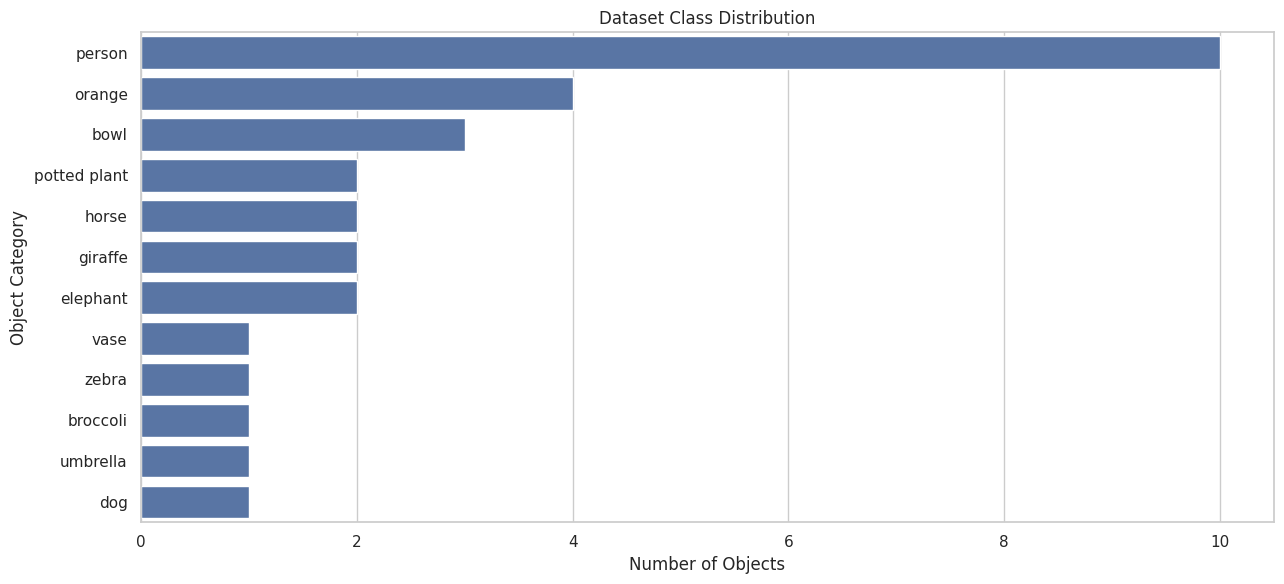


IMAGE QUALITY REPORT
-------------------------------------------------------
            Width      Height  Brightness     Sharpness     Resolution
count    8.000000    8.000000    8.000000      8.000000       8.000000
mean   587.750000  483.125000  125.789630   8370.441141  280292.500000
std    100.371809   70.340879   16.311791   8917.237209   40348.545646
min    381.000000  425.000000  101.599696    834.745335  190500.000000
25%    600.250000  427.500000  116.220044   2144.376387  272480.000000
50%    640.000000  479.000000  125.363965   6625.770589  289920.000000
75%    640.000000  491.000000  141.886636   9744.180125  307360.000000
max    640.000000  640.000000  143.254034  27971.702385  312320.000000


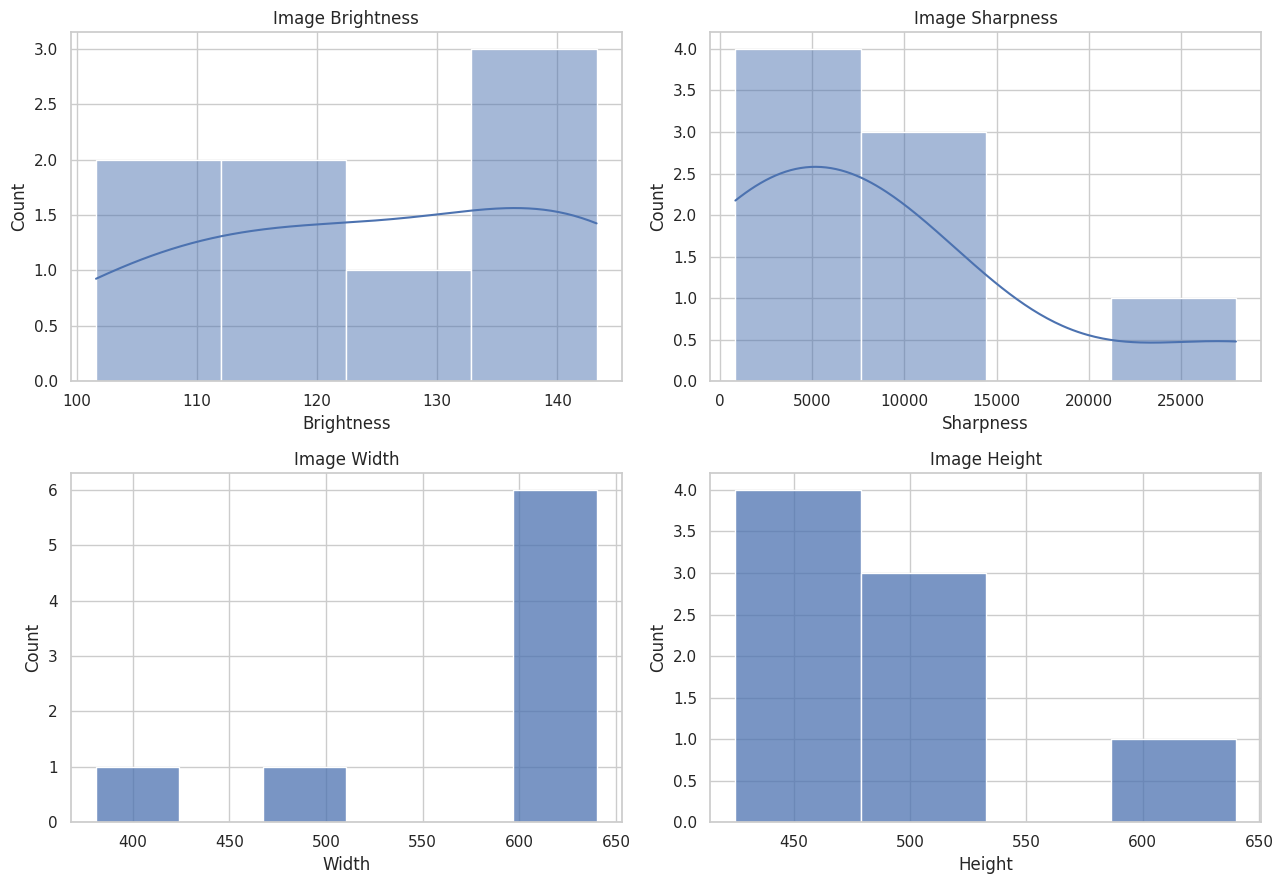

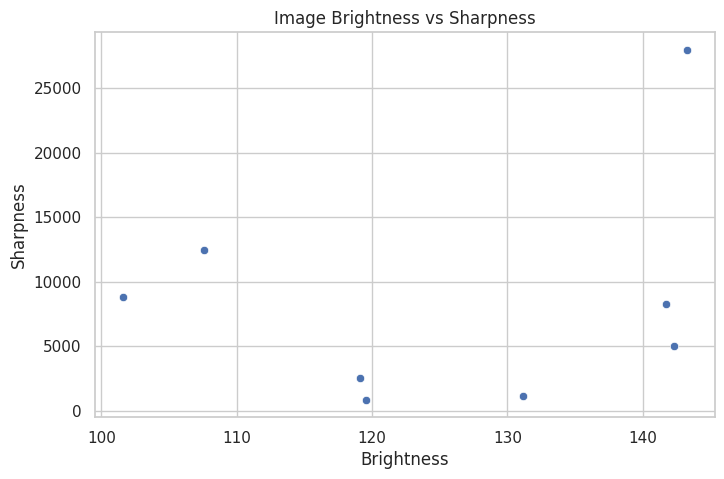


ANNOTATION VALIDATION
-------------------------------------------------------
Total Bounding Boxes: 30
Valid Bounding Boxes: 30
Invalid Bounding Boxes: 0


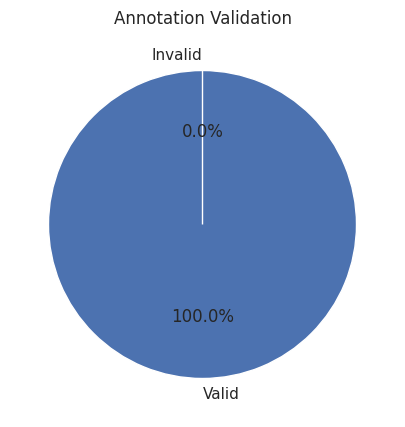


GROUND-TRUTH ANNOTATED DATASET IMAGES


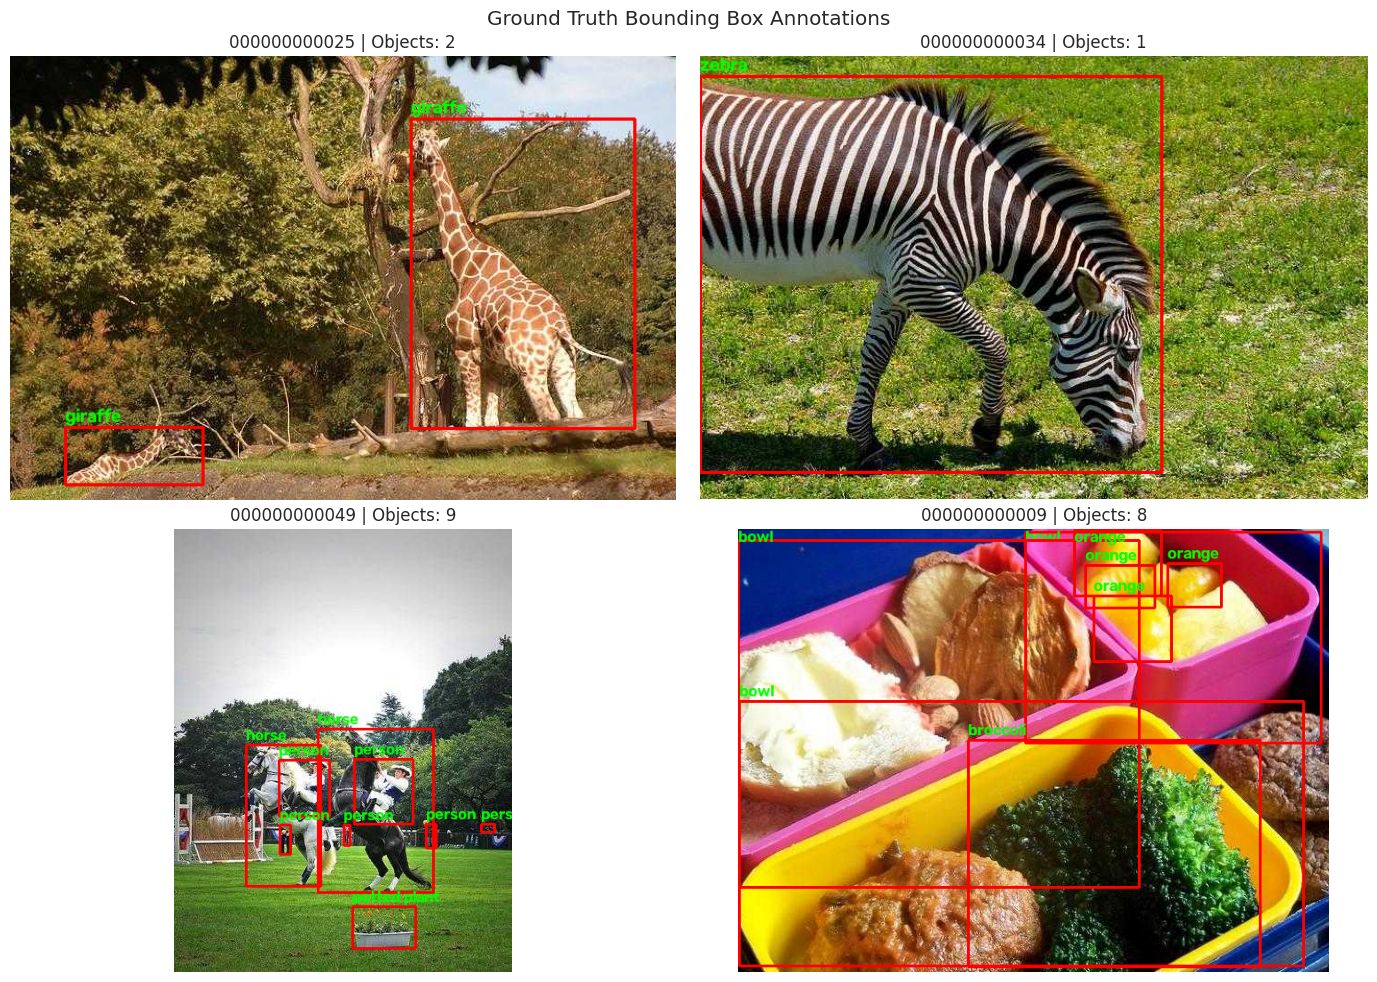


PROCESSING SELECTED IMAGE USING YOLO
-------------------------------------------------------


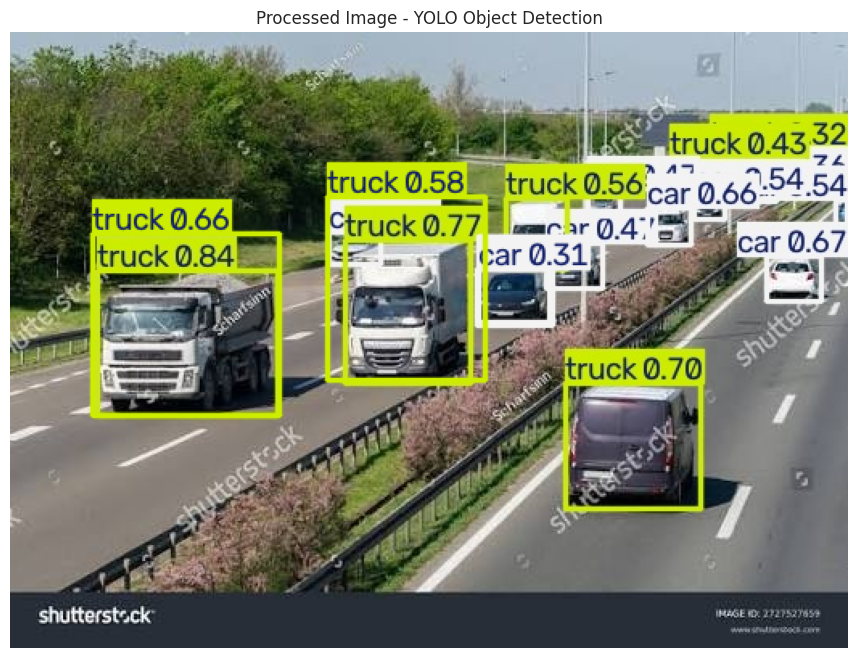


DETECTED OBJECTS


,Object,Confidence,Bounding Box
0,truck,0.662,[ 51.2 125.7 167 238.2]
1,truck,0.583,[ 197.8 102.9 295.4 216.8]
2,car,0.306,[ 291.6 147.2 335.6 180.9]



 FINAL DATASET AUDIT DASHBOARD
Dataset: COCO8 / Uploaded YOLO Dataset
Total Images: 8
Readable Images: 8
Total Classes: 12
Total Annotations: 30
Valid Annotations: 30
Invalid Annotations: 0
Detected Objects in Uploaded Image: 3

EXPERIMENT COMPLETED SUCCESSFULLY!

REPORT FILES GENERATED:
1. image_quality_report.csv
2. class_distribution_report.csv
3. invalid_annotations_report.csv
4. detection_results.csv
5. annotated_output.jpg

Download your annotated image and reports below.

FINAL PROCESSED IMAGE


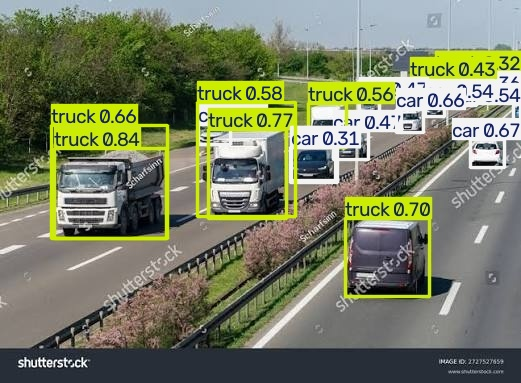

Annotated image displayed successfully!


In [6]:

# ==============================================================
# EXPERIMENT: DATASET AUDIT AND VISUALISATION
# Class Distribution | Image Quality | Annotation Validation
# Dataset: COCO8 (Real Images)
# ==============================================================

!pip -q install ultralytics seaborn opencv-python-headless

import os, glob, zipfile, random, shutil
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from ultralytics import YOLO
from IPython.display import display
from collections import Counter

random.seed(42)
sns.set_style("whitegrid")

# --------------------------------------------------------------
# 1. DOWNLOAD SAMPLE DATASET AND MODEL
# --------------------------------------------------------------

print("="*65)
print(" DATASET AUDIT AND VISUALISATION EXPERIMENT")
print("="*65)

print("\nDownloading COCO8 real-image dataset...")

if not os.path.exists("/content/coco8"):
    import urllib.request
    urllib.request.urlretrieve(
        "https://github.com/ultralytics/assets/releases/download/v0.0.0/coco8.zip",
        "/content/coco8.zip"
    )
    with zipfile.ZipFile("/content/coco8.zip") as z:
        z.extractall("/content")

dataset = "/content/coco8"

print("COCO8 dataset downloaded successfully!")

print("\nLoading YOLO object detection model...")
model = YOLO("yolov8n.pt")
print("Model loaded successfully!")

# --------------------------------------------------------------
# 2. ASK FOR DATASET
# --------------------------------------------------------------

print("\nDATASET SELECTION")
print("1. Use supplied COCO8 dataset")
print("2. Upload your own YOLO-format dataset ZIP")

choice = input("Enter choice (1 or 2): ").strip()

if choice == "2":
    print("\nUpload your dataset ZIP:")
    uploaded = files.upload()

    zip_file = list(uploaded.keys())[0]
    custom_path = "/content/custom_dataset"

    if os.path.exists(custom_path):
        shutil.rmtree(custom_path)

    os.makedirs(custom_path)

    with zipfile.ZipFile(zip_file) as z:
        z.extractall(custom_path)

    dataset = custom_path

# Find dataset images and labels
image_files = []
label_files = []

for root, dirs, filenames in os.walk(dataset):
    for f in filenames:
        full = os.path.join(root, f)

        if f.lower().endswith((".jpg", ".jpeg", ".png")):
            image_files.append(full)

        elif f.endswith(".txt"):
            label_files.append(full)

# Only use TXT files inside labels directories
label_files = [
    p for p in label_files
    if "labels" in p.lower()
]

print("\nDataset Images:", len(image_files))
print("Annotation Files:", len(label_files))

if not image_files:
    raise ValueError("No images found in the dataset.")

# --------------------------------------------------------------
# 3. ASK FOR IMAGE TO PROCESS
# --------------------------------------------------------------

print("\nIMAGE SELECTION")
print("1. Use a sample image from the supplied dataset")
print("2. Upload your own image")

image_choice = input("Enter choice (1 or 2): ").strip()

if image_choice == "2":
    print("\nUpload an image (JPG/PNG):")
    uploaded_image = files.upload()
    image_path = list(uploaded_image.keys())[0]
else:
    image_path = random.choice(image_files)

print("\nSelected Image:", os.path.basename(image_path))

# --------------------------------------------------------------
# 4. CLASS DISTRIBUTION
# --------------------------------------------------------------

class_counts = Counter()
total_boxes = 0
valid_boxes = 0
invalid_boxes = 0
invalid_details = []

label_to_image = {}

# Match labels to images by filename
for img in image_files:
    label_to_image[os.path.splitext(os.path.basename(img))[0]] = img

for label_path in label_files:
    try:
        with open(label_path, "r") as f:
            lines = f.readlines()

        for line_number, line in enumerate(lines, 1):
            parts = line.strip().split()

            if not parts:
                continue

            total_boxes += 1

            try:
                values = list(map(float, parts))
                class_id = int(values[0])

                if len(values) != 5:
                    raise ValueError("Incorrect annotation format")

                x, y, w, h = values[1:]

                if (not np.all(np.isfinite(values)) or
                    class_id < 0 or
                    w <= 0 or h <= 0 or
                    x < 0 or x > 1 or
                    y < 0 or y > 1 or
                    x + w/2 > 1 or
                    y + h/2 > 1):
                    raise ValueError("Invalid bounding box")

                valid_boxes += 1
                class_counts[class_id] += 1

            except Exception as e:
                invalid_boxes += 1
                invalid_details.append({
                    "File": os.path.basename(label_path),
                    "Line": line_number,
                    "Error": str(e)
                })

    except Exception as e:
        print("Could not read:", label_path)

print("\nCLASS DISTRIBUTION")
print("-"*55)

if class_counts:
    class_df = pd.DataFrame(
        class_counts.items(),
        columns=["Class ID", "Object Count"]
    ).sort_values("Object Count", ascending=False)

    class_df["Class Name"] = class_df["Class ID"].map(
        lambda x: model.names.get(x, f"Class {x}")
    )

    plt.figure(figsize=(13, 6))
    sns.barplot(
        data=class_df,
        x="Object Count",
        y="Class Name"
    )
    plt.title("Dataset Class Distribution")
    plt.xlabel("Number of Objects")
    plt.ylabel("Object Category")
    plt.tight_layout()
    plt.show()
else:
    class_df = pd.DataFrame()
    print("No valid class annotations found.")

# --------------------------------------------------------------
# 5. IMAGE QUALITY AUDIT
# --------------------------------------------------------------

quality = []

for path in image_files:
    img = cv2.imread(path)

    if img is None:
        continue

    h, w = img.shape[:2]
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    brightness = np.mean(gray)
    sharpness = cv2.Laplacian(
        gray, cv2.CV_64F
    ).var()

    quality.append({
        "Image": os.path.basename(path),
        "Width": w,
        "Height": h,
        "Brightness": brightness,
        "Sharpness": sharpness,
        "Resolution": w*h
    })

quality_df = pd.DataFrame(quality)

print("\nIMAGE QUALITY REPORT")
print("-"*55)
print(quality_df.describe())

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

sns.histplot(quality_df["Brightness"], kde=True,
             ax=axes[0, 0])
axes[0, 0].set_title("Image Brightness")

sns.histplot(quality_df["Sharpness"], kde=True,
             ax=axes[0, 1])
axes[0, 1].set_title("Image Sharpness")

sns.histplot(quality_df["Width"], ax=axes[1, 0])
axes[1, 0].set_title("Image Width")

sns.histplot(quality_df["Height"], ax=axes[1, 1])
axes[1, 1].set_title("Image Height")

plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=quality_df,
    x="Brightness",
    y="Sharpness"
)
plt.title("Image Brightness vs Sharpness")
plt.show()

# --------------------------------------------------------------
# 6. ANNOTATION VALIDATION GRAPH
# --------------------------------------------------------------

print("\nANNOTATION VALIDATION")
print("-"*55)
print("Total Bounding Boxes:", total_boxes)
print("Valid Bounding Boxes:", valid_boxes)
print("Invalid Bounding Boxes:", invalid_boxes)

plt.figure(figsize=(7, 5))
plt.pie(
    [valid_boxes, invalid_boxes],
    labels=["Valid", "Invalid"],
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Annotation Validation")
plt.show()

# --------------------------------------------------------------
# 7. GROUND-TRUTH ANNOTATION IMAGES
# --------------------------------------------------------------

print("\nGROUND-TRUTH ANNOTATED DATASET IMAGES")

sample_files = random.sample(
    image_files, min(4, len(image_files))
)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for ax, path in zip(axes, sample_files):

    img = cv2.imread(path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    name = os.path.splitext(os.path.basename(path))[0]

    matching_labels = [
        p for p in label_files
        if os.path.splitext(os.path.basename(p))[0] == name
    ]

    count = 0

    if matching_labels:
        with open(matching_labels[0]) as f:
            for line in f:
                parts = line.split()

                try:
                    cls, x, y, w, h = map(float, parts)

                    if len(parts) != 5:
                        continue

                    H, W = img.shape[:2]

                    x1 = int((x-w/2)*W)
                    y1 = int((y-h/2)*H)
                    x2 = int((x+w/2)*W)
                    y2 = int((y+h/2)*H)

                    cv2.rectangle(
                        img, (x1, y1), (x2, y2),
                        (255, 0, 0), 2
                    )

                    label = model.names.get(
                        int(cls), str(int(cls))
                    )

                    cv2.putText(
                        img, label,
                        (x1, max(y1-5, 15)),
                        cv2.FONT_HERSHEY_SIMPLEX,
                        0.6, (0, 255, 0), 2
                    )

                    count += 1

                except:
                    pass

    ax.imshow(img)
    ax.set_title(f"{name} | Objects: {count}")
    ax.axis("off")

for ax in axes[len(sample_files):]:
    ax.axis("off")

plt.suptitle("Ground Truth Bounding Box Annotations")
plt.tight_layout()
plt.show()

# --------------------------------------------------------------
# 8. PROCESS SELECTED IMAGE USING YOLO
# --------------------------------------------------------------

print("\nPROCESSING SELECTED IMAGE USING YOLO")
print("-"*55)

result = model.predict(
    source=image_path,
    conf=0.25,
    save=False,
    verbose=False
)[0]

annotated = result.plot()
annotated = cv2.cvtColor(
    annotated, cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(12, 8))
plt.imshow(annotated)
plt.title("Processed Image - YOLO Object Detection")
plt.axis("off")
plt.show()

# Detected object information
detections = []

for box in result.boxes:
    cls = int(box.cls[0])
    confidence = float(box.conf[0])
    xyxy = box.xyxy[0].cpu().numpy()

    detections.append({
        "Object": model.names[cls],
        "Confidence": round(confidence, 3),
        "Bounding Box": str(xyxy.round(1))
    })

print("\nDETECTED OBJECTS")
if detections:
    display(pd.DataFrame(detections))
else:
    print("No objects detected in this image.")

# --------------------------------------------------------------
# 9. FINAL DATASET AUDIT DASHBOARD
# --------------------------------------------------------------

print("\n" + "="*65)
print(" FINAL DATASET AUDIT DASHBOARD")
print("="*65)

print("Dataset: COCO8 / Uploaded YOLO Dataset")
print("Total Images:", len(image_files))
print("Readable Images:", len(quality_df))
print("Total Classes:", len(class_counts))
print("Total Annotations:", total_boxes)
print("Valid Annotations:", valid_boxes)
print("Invalid Annotations:", invalid_boxes)
print("Detected Objects in Uploaded Image:", len(detections))

print("\nEXPERIMENT COMPLETED SUCCESSFULLY!")

# --------------------------------------------------------------
# 10. SAVE REPORTS
# --------------------------------------------------------------

quality_df.to_csv(
    "/content/image_quality_report.csv", index=False
)

class_df.to_csv(
    "/content/class_distribution_report.csv", index=False
)

pd.DataFrame(invalid_details).to_csv(
    "/content/invalid_annotations_report.csv",
    index=False
)

pd.DataFrame(detections).to_csv(
    "/content/detection_results.csv", index=False
)

cv2.imwrite(
    "/content/annotated_output.jpg",
    cv2.cvtColor(annotated, cv2.COLOR_RGB2BGR)
)

print("\nREPORT FILES GENERATED:")
print("1. image_quality_report.csv")
print("2. class_distribution_report.csv")
print("3. invalid_annotations_report.csv")
print("4. detection_results.csv")
print("5. annotated_output.jpg")

print("\nDownload your annotated image and reports below.")

# DISPLAY ANNOTATED OUTPUT DIRECTLY ON SCREEN

from IPython.display import display, Image

print("\nFINAL PROCESSED IMAGE")

display(Image(filename="/content/annotated_output.jpg"))

print("Annotated image displayed successfully!")
